In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input/student-mark'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session
df = pd.read_csv("/kaggle/input/student-marks-dataset/Student_Marks.csv")
print(df)

    number_courses  time_study   Marks
0                3       4.508  19.202
1                4       0.096   7.734
2                4       3.133  13.811
3                6       7.909  53.018
4                8       7.811  55.299
..             ...         ...     ...
95               6       3.561  19.128
96               3       0.301   5.609
97               4       7.163  41.444
98               7       0.309  12.027
99               3       6.335  32.357

[100 rows x 3 columns]


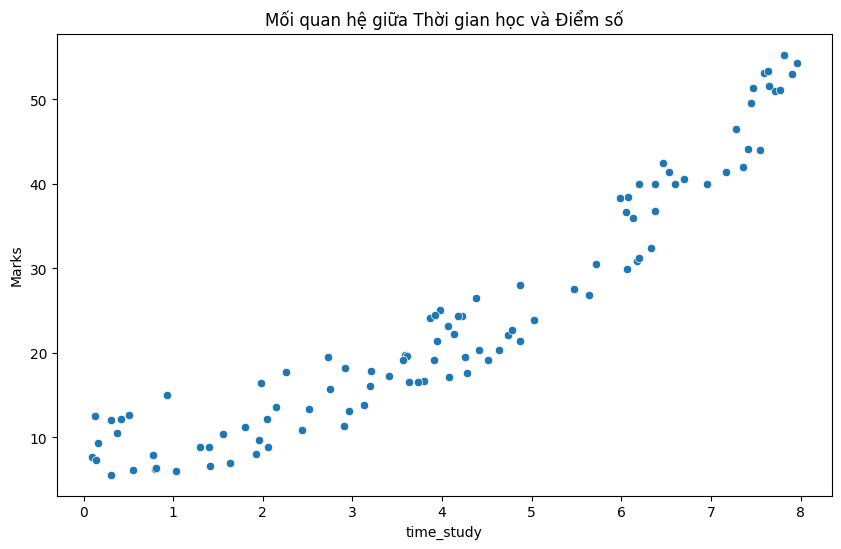

In [2]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='time_study',y='Marks')
plt.title('Mối quan hệ giữa Thời gian học và Điểm số')
plt.show()

<Figure size 800x500 with 0 Axes>

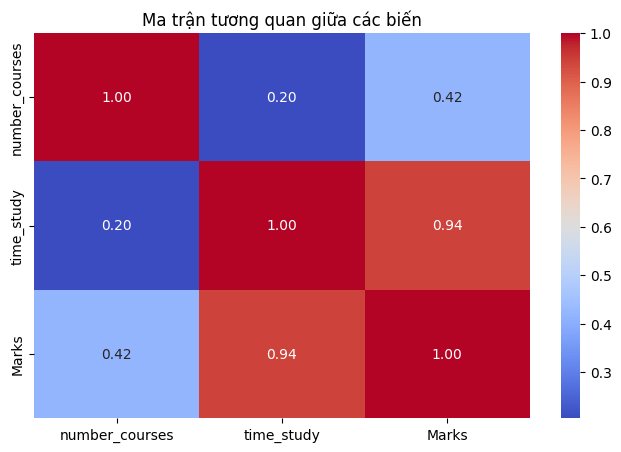

In [3]:
plt.figure(figsize=(8,5))
plt.figure(figsize=(8, 5))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Ma trận tương quan giữa các biến')
plt.show()

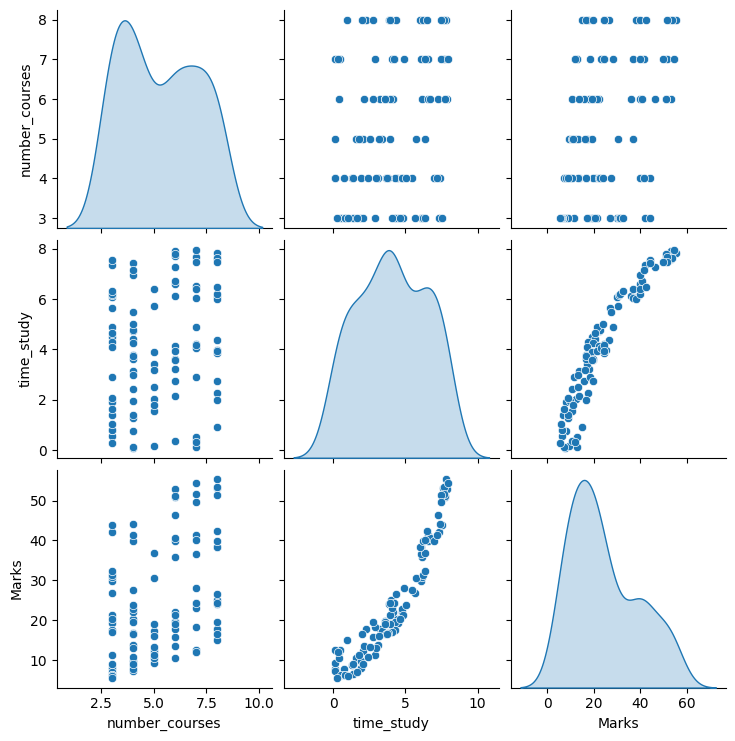

In [4]:
sns.pairplot(df, diag_kind='kde')
plt.show()

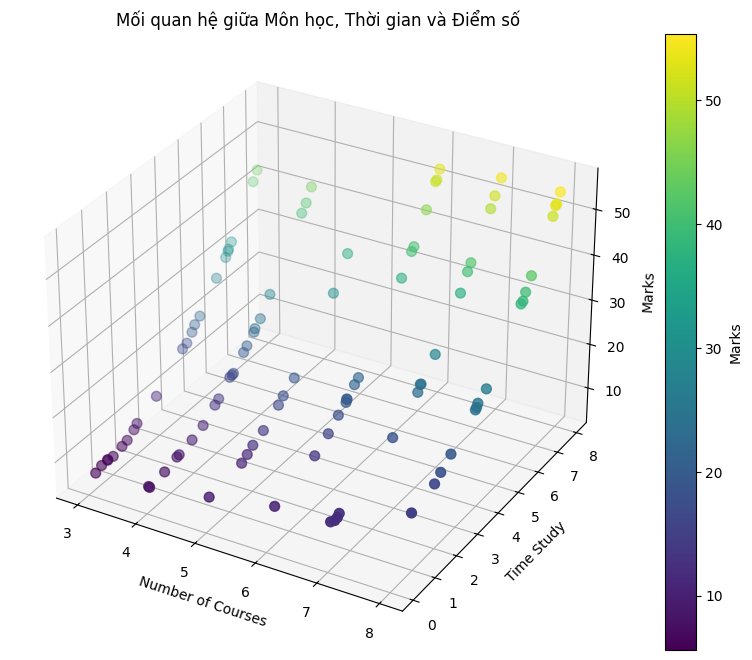

In [5]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(df['number_courses'], 
                    df['time_study'], 
                    df['Marks'], 
                    c=df['Marks'],
                    cmap='viridis', 
                    s=50) 


ax.set_xlabel('Number of Courses')
ax.set_ylabel('Time Study')
ax.set_zlabel('Marks')
ax.set_title('Mối quan hệ giữa Môn học, Thời gian và Điểm số')


fig.colorbar(scatter, ax=ax, label='Marks')

plt.show()

In [6]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [7]:
X = df[['time_study', 'Marks']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [8]:
from sklearn.decomposition import PCA
pca = PCA(n_components=1)
df['Performance_Score'] = pca.fit_transform(X_scaled)

X_final = df[['Performance_Score', 'number_courses']].copy()
scaler_final = StandardScaler()
X_final_scaled = scaler_final.fit_transform(X_final)

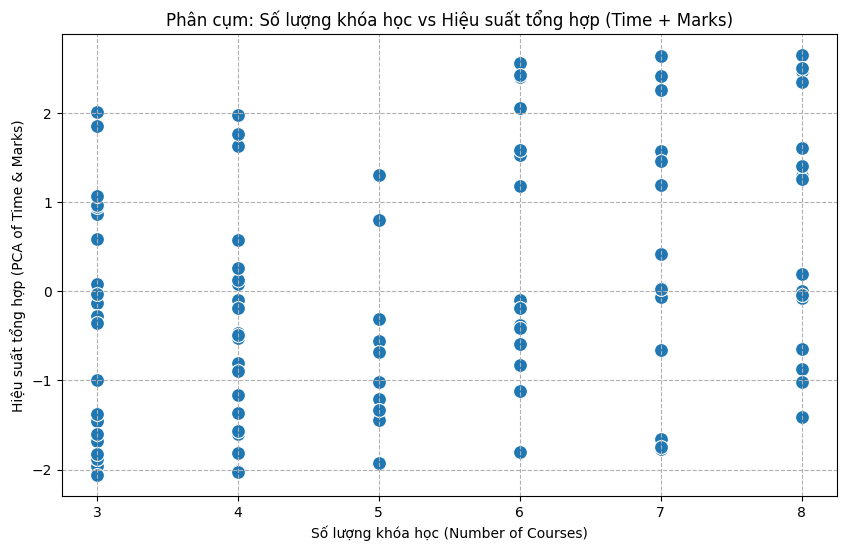

In [9]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='number_courses', y='Performance_Score', s=100)
plt.title('Phân cụm: Số lượng khóa học vs Hiệu suất tổng hợp (Time + Marks)')
plt.xlabel('Số lượng khóa học (Number of Courses)')
plt.ylabel('Hiệu suất tổng hợp (PCA of Time & Marks)')
plt.grid(True, linestyle='--')
plt.show()

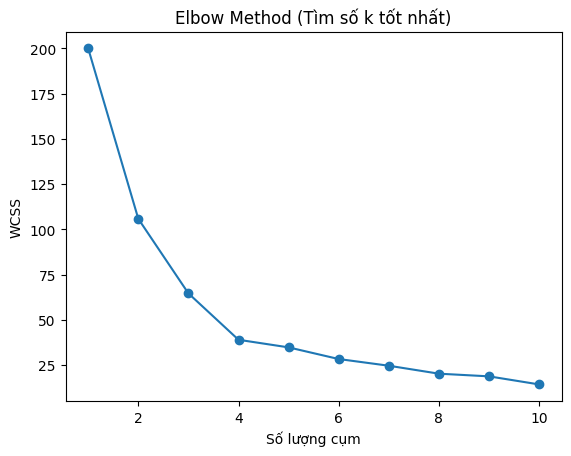

In [10]:
wcss = []
for i in range(1, 11):
    km = KMeans(n_clusters=i, init='k-means++', random_state=42)
    km.fit(X_final_scaled)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method (Tìm số k tốt nhất)')
plt.xlabel('Số lượng cụm')
plt.ylabel('WCSS')
plt.show()

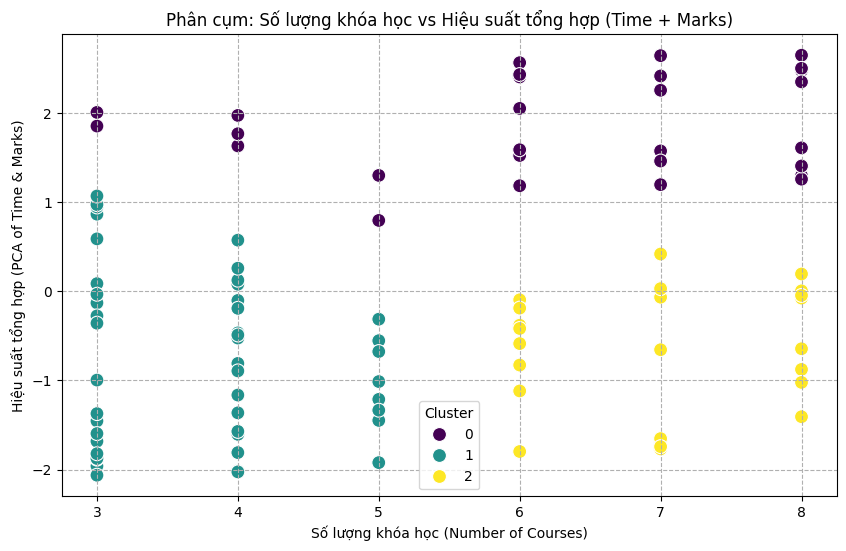

In [11]:

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_final_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='number_courses', y='Performance_Score', hue='Cluster', palette='viridis', s=100)
plt.title('Phân cụm: Số lượng khóa học vs Hiệu suất tổng hợp (Time + Marks)')
plt.xlabel('Số lượng khóa học (Number of Courses)')
plt.ylabel('Hiệu suất tổng hợp (PCA of Time & Marks)')
plt.grid(True, linestyle='--')
plt.show()

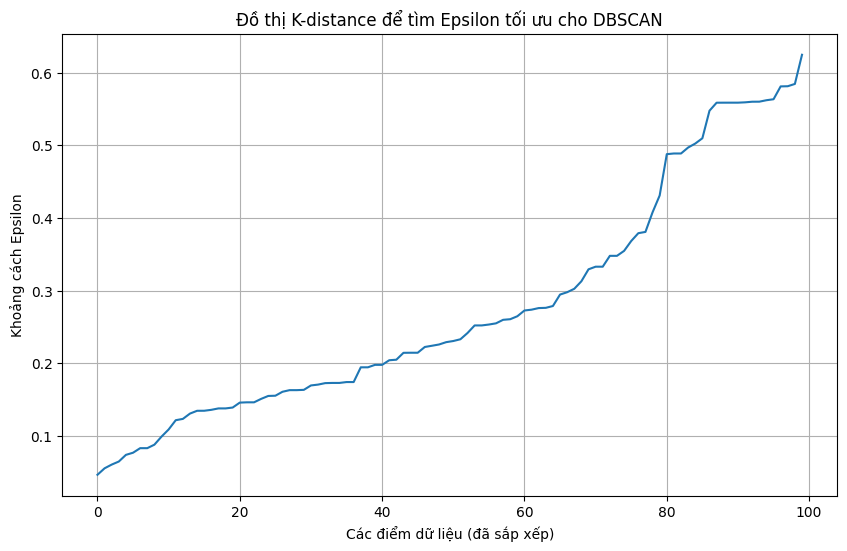

In [12]:
from sklearn.neighbors import NearestNeighbors
neighbors = NearestNeighbors(n_neighbors=4)
neighbors_fit = neighbors.fit(X_final_scaled)
distances, indices = neighbors_fit.kneighbors(X_final_scaled)
distances = np.sort(distances[:, 3], axis=0)

plt.figure(figsize=(10, 6))
plt.plot(distances)
plt.title('Đồ thị K-distance để tìm Epsilon tối ưu cho DBSCAN')
plt.xlabel('Các điểm dữ liệu (đã sắp xếp)')
plt.ylabel('Khoảng cách Epsilon')
plt.grid(True)
plt.show()

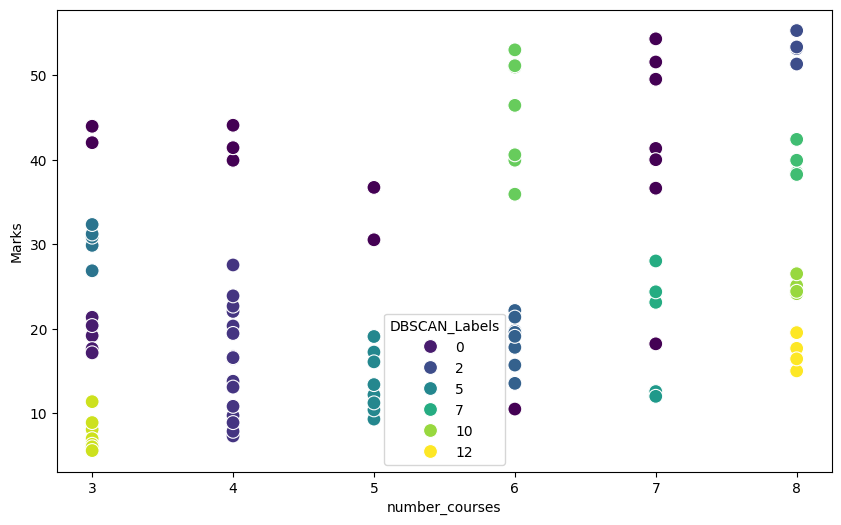

In [13]:
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=0.35, min_samples=4) 
df['DBSCAN_Labels'] = dbscan.fit_predict(X_final_scaled)

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='number_courses', y='Marks', hue='DBSCAN_Labels', palette='viridis',  s=100)
plt.show()


In [14]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, kmeans.labels_)
print(f"Silhouette Score(K-Means): {score:.2f}")
score = silhouette_score(X_scaled, dbscan.labels_)
print(f"Silhouette Score(DB-SCAN): {score:.2f}")

Silhouette Score(K-Means): 0.21
Silhouette Score(DB-SCAN): -0.12
